# DAY3 실습 04 — 독립표본 Welch t검정

In [2]:
%pip install -q koreanize-matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

In [3]:
import os

from google.colab import drive

drive.mount("/content/drive")
data_folder = "/content/drive/MyDrive/HD_AX_S/data"
csv_path = os.path.join(data_folder, "Steel_industry_data.csv")

df = pd.read_csv(csv_path)

data = df.copy()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 데이터와 질문

데이터 파일 : `Steel_industry_data.csv`
출처 : UCI Machine Learning Repository - [Steel Industry Energy Consumption](https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption)

한 철강 공장의 2018년 전력 사용 기록이다. 15분마다 1건씩 기록되어 있다.

| 열 | 뜻 |
|---|---|
| `date` | 기록 시각 (일/월/연 시:분) |
| `Usage_kWh` | 15분 동안의 전력 사용량 (kWh) |
| `WeekStatus` | 평일(Weekday) · 주말(Weekend) |
| `Day_of_week` | 요일 (Monday ~ Sunday) |

**질문** : 평일 하루 전력 사용량의 평균은 상반기(1 ~ 6월)와 하반기(7 ~ 12월)에 다른가?

**실습 전제** : 하루를 대상 하나로 본다. 상반기의 날과 하반기의 날은 서로 다른 날이다. 여기서는 무작위로 뽑은 날짜별 관측값이 서로 독립이라고 가정한다. 실제 분석에서는 시간에 따른 의존성도 확인한다. 각 집단에서 날짜를 무작위로 뽑아 표본으로 쓴다.

In [4]:
# 데이터 확인 : 행·열 수, 사용량 결측, 요일별 기록 수
print("행·열:", data.shape)
print("사용량 결측:", data["Usage_kWh"].isna().sum())
print(data["Day_of_week"].value_counts())                 # 요일별 기록 수

행·열: (35040, 11)
사용량 결측: 0
Day_of_week
Monday       5088
Tuesday      4992
Wednesday    4992
Thursday     4992
Friday       4992
Saturday     4992
Sunday       4992
Name: count, dtype: int64


## 1. Welch t검정 : 독립된 두 집단의 평균 비교

**Welch t검정**은 서로 독립인 두 집단의 모집단 평균을 비교하는 검정이며, 두 집단의 분산이 같다고 가정하지 않는다.

| 용어 | 뜻 |
|---|---|
| 독립 | 한 집단의 관측값이 다른 집단의 관측값과 짝을 이루지 않고 서로 영향을 주지 않는다 (예 : 카페 A 고객과 카페 B 고객은 서로 다른 사람이다) |
| 등분산 | 두 모집단의 분산(퍼짐 정도)이 같다는 뜻이다 |
| Welch t검정 | 등분산을 가정하지 않는다. 두 집단의 표본 크기와 퍼짐이 달라도 쓸 수 있다 |

**가설 형식**

- 귀무가설(H₀): 두 모집단의 평균은 같다. (μA = μB)
- 대립가설(H₁): 두 모집단의 평균은 다르다. (μA ≠ μB)

**정규성 확인** : 두 집단 **각각**의 분포를 확인한다. 정규성 검정의 p값만으로 검정 방법을 결정하지 않는다. 평균 차이가 관심 대상인지, 표본 크기·분포 모양·극단값 등을 종합하여 Welch t검정의 적절성을 판단한다. 두 집단의 분포를 비교하려는 목적이라면 Mann-Whitney U 검정도 고려할 수 있지만, 이는 평균 차이를 검정하는 방법이 아니다.

| 함수 | 기능 |
|---|---|
| `stats.ttest_ind(A, B, equal_var=False)` | Welch t검정. 평균 차이를 A − B 순서로 계산한다. `equal_var=False`가 Welch 방식이다 |
| `결과.df` | Welch 자유도. 두 집단의 크기와 분산으로 계산하므로 소수로 나온다 |
| `결과.confidence_interval(confidence_level=0.95)` | 모평균 차이(μA − μB)의 신뢰구간 |

`ttest_ind`의 기본값은 `equal_var=True`(등분산을 가정하는 방식)이므로 `equal_var=False`를 꼭 적는다.

공식 문서 : [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)

In [5]:
# [예제] 카페 A · B 고객 각 8명의 대기시간(분)을 비교한다. 두 집단의 고객은 서로 다른 사람이다
# 귀무가설(H₀): 카페 A와 카페 B의 모집단 평균 대기시간은 같다. (μA = μB)
# 대립가설(H₁): 카페 A와 카페 B의 모집단 평균 대기시간은 다르다. (μA ≠ μB)
# 유의수준 α = 0.05, 양측
cafe_a = np.array([4, 5, 6, 5, 4, 6, 5, 5])        # 카페 A 고객 8명
cafe_b = np.array([7, 8, 6, 7, 8, 7, 9, 6])        # 카페 B 고객 8명

print("A 평균:", round(cafe_a.mean(), 2), "/ B 평균:", round(cafe_b.mean(), 2), "/ 차이(A − B):", round(cafe_a.mean() - cafe_b.mean(), 2), "분")

# 정규성 확인 : 두 집단 각각
# 귀무가설(H₀): 각 카페의 대기시간은 정규분포를 따른다.
# 대립가설(H₁): 각 카페의 대기시간은 정규분포를 따르지 않는다.
print("A Shapiro-Wilk p값:", round(stats.shapiro(cafe_a).pvalue, 3), "/ B Shapiro-Wilk p값:", round(stats.shapiro(cafe_b).pvalue, 3))

cafe_result = stats.ttest_ind(cafe_a, cafe_b, equal_var=False)       # Welch t검정. A − B 순서
cafe_ci = cafe_result.confidence_interval(confidence_level=0.95)      # 모평균 차이(μA − μB)의 95% 신뢰구간
print("t:", round(cafe_result.statistic, 2), "/ p값:", round(cafe_result.pvalue, 5), "/ 자유도:", round(cafe_result.df, 2))
print("평균 차이 95% 신뢰구간:", round(cafe_ci.low, 2), "~", round(cafe_ci.high, 2), "분")

# [결과]
# - A 평균 5.0분, B 평균 7.25분, 차이(A − B) −2.25분. Shapiro-Wilk A p = 0.093, B p = 0.408 → 둘 다 0.05 이상으로 정규성을 기각할 근거는 부족하다. 정규성을 입증한 것은 아니며, 분포 모양·극단값도 함께 살펴 평균 비교를 위한 Welch t검정을 적용한다
# - t = −4.97, 자유도 12.81, p = 0.00027, 95% 신뢰구간 −3.23 ~ −1.27분
# - 통계적 결론 : p = 0.00027 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 카페 A와 카페 B의 모집단 평균 대기시간은 다르다고 볼 통계적 근거가 있다. 표본에서 카페 A의 평균 대기시간이 카페 B보다 2.25분 짧았다 (95% 신뢰구간 −3.23 ~ −1.27분, 각 8명)

A 평균: 5.0 / B 평균: 7.25 / 차이(A − B): -2.25 분
A Shapiro-Wilk p값: 0.093 / B Shapiro-Wilk p값: 0.408
t: -4.97 / p값: 0.00027 / 자유도: 12.81
평균 차이 95% 신뢰구간: -3.23 ~ -1.27 분


## 2. 평일 하루 사용량 표 만들기

15분 단위 기록을 **날짜 하나에 한 행**인 표로 바꾸고, 월(month) 정보를 붙여 상반기와 하반기로 나눈다.

| 집단 | 포함하는 날 |
|---|---|
| 상반기 | 1 ~ 6월의 평일 |
| 하반기 | 7 ~ 12월의 평일 |

| 함수 | 기능 |
|---|---|
| `data["date"].dt.month` | 날짜·시각에서 월(1 ~ 12)만 꺼낸다 |
| `data.groupby(["day", "month"])["Usage_kWh"].sum().reset_index()` | 날짜별 사용량 합계를 구하고, 날짜·월을 다시 열로 꺼낸다 |

공식 문서 : [Series.dt.month](https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.month.html) · [DataFrame.groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html) · [DataFrame.reset_index](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reset_index.html)

In [6]:
# [예제] 평일 날짜별 하루 사용량 표를 만들고 상반기 · 하반기로 나눈다
data["date"] = pd.to_datetime(data["date"], format="%d/%m/%Y %H:%M")   # 문자열 → 날짜·시각 형식
data["day"] = data["date"].dt.date                                      # 날짜
data["month"] = data["date"].dt.month                                   # 월 (1 ~ 12)

weekday = data.loc[data["WeekStatus"] == "Weekday"]                     # 평일 기록만
daily = weekday.groupby(["day", "month"])["Usage_kWh"].sum().reset_index()   # 날짜별 하루 사용량. 날짜 · 월 · 사용량 세 열

first_half = daily.loc[daily["month"] <= 6, "Usage_kWh"]                # 상반기 평일의 하루 사용량
second_half = daily.loc[daily["month"] >= 7, "Usage_kWh"]               # 하반기 평일의 하루 사용량
print("상반기 일수:", len(first_half), "/ 하반기 일수:", len(second_half))
print(daily.head())

# [결과]
# - 평일 261일 중 상반기 130일, 하반기 131일

상반기 일수: 130 / 하반기 일수: 131
          day  month  Usage_kWh
0  2018-01-01      1     351.86
1  2018-01-02      1    3950.43
2  2018-01-03      1    3561.05
3  2018-01-04      1    4977.72
4  2018-01-05      1    4683.40


## 3. Welch t검정 실습 : 상반기와 하반기

상반기 130일에서 25일, 하반기 131일에서 15일을 뽑아 4단계로 검정한다. 평균 차이는 **상반기 − 하반기**로 정한다.

1) 가설 설정 (μ₁ : 상반기 평일 하루 사용량의 모평균, μ₂ : 하반기 평일 하루 사용량의 모평균)
   - 귀무가설(H₀): 상반기와 하반기 평일 하루 전력 사용량의 모집단 평균은 같다. (μ₁ = μ₂)
   - 대립가설(H₁): 상반기와 하반기 평일 하루 전력 사용량의 모집단 평균은 다르다. (μ₁ ≠ μ₂)
2) 유의수준 : α = 0.05, 양측
3) 정규성 확인 → 검정 : 두 집단 각각 히스토그램 · Q-Q 플롯 · Shapiro-Wilk 검정 → `stats.ttest_ind(..., equal_var=False)`
4) 결과 도출 : p값, 평균 차이, 신뢰구간으로 두 줄 결론을 쓴다

공식 문서 : [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html) · [scipy.stats.probplot](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.probplot.html)

In [12]:
# [실습]
# 상황 : Welch t검정은 두 집단 각각의 정규성을 확인한다. 상반기와 하반기에서 날짜를 뽑아 분포를 먼저 본다.
#        귀무가설(H₀): 각 집단(상반기, 하반기)의 하루 사용량은 정규분포를 따른다.
#        대립가설(H₁): 각 집단(상반기, 하반기)의 하루 사용량은 정규분포를 따르지 않는다. (α = 0.05)
# first_half 에서 25일, second_half 에서 15일을 뽑아(둘 다 random_state=9) h1, h2 로 저장하시오.
# 2행 2열 그래프로 집단마다 히스토그램과 Q-Q 플롯을 그리고, 집단마다 Shapiro-Wilk 검정의 p값을 구하시오.

h1 = first_half.sample(n=25, replace=False, random_state=9)     # 상반기 25일
h2 = second_half.sample(n=15, replace=False, random_state=9)    # 하반기 15일
print("상반기 Shapiro-Wilk p값:", round(stats.shapiro(h1).pvalue, 4))
print("하반기 Shapiro-Wilk p값:", round(stats.shapiro(h2).pvalue, 4))

상반기 Shapiro-Wilk p값: 0.903
하반기 Shapiro-Wilk p값: 0.5939


In [13]:
# [실습]
# 상황 : 두 집단의 정규성이 크게 어긋나지 않으므로 Welch t검정으로 상반기와 하반기의 하루 사용량을 비교한다.
#        귀무가설(H₀): 상반기와 하반기 평일 하루 전력 사용량의 모집단 평균은 같다. (μ₁ = μ₂)
#        대립가설(H₁): 상반기와 하반기 평일 하루 전력 사용량의 모집단 평균은 다르다. (μ₁ ≠ μ₂)
#        유의수준 α = 0.05, 양측
# 집단별 평균 · 표준편차와 평균 차이(상반기 − 하반기)를 구하고, Welch t검정의 t, p값, 자유도와 평균 차이의 95% 신뢰구간을 구하시오.

print("상반기 평균:", round(h1.mean(), 1), "kWh / 표준편차:", round(h1.std(), 1), "kWh")
print("하반기 평균:", round(h2.mean(), 1), "kWh / 표준편차:", round(h2.std(), 1), "kWh")
print("평균 차이(상반기 − 하반기):", round(h1.mean() - h2.mean(), 1), "kWh")

half_result = stats.ttest_ind(h1, h2, equal_var=False)
half_ci = half_result.confidence_interval(confidence_level=0.95)
print("t:", round(half_result.statistic, 3), "/ p값:", round(half_result.pvalue, 4), "/ 자유도:", round(half_result.df, 1))
print("평균 차이 95% 신뢰구간:", round(half_ci.low, 1), "~", round(half_ci.high, 1), "kWh")

상반기 평균: 3939.2 kWh / 표준편차: 1152.3 kWh
하반기 평균: 2976.2 kWh / 표준편차: 537.5 kWh
평균 차이(상반기 − 하반기): 962.9 kWh
t: 3.579 / p값: 0.001 / 자유도: 36.4
평균 차이 95% 신뢰구간: 417.5 ~ 1508.3 kWh


In [9]:
# [실습]
# 상황 : 위 검정 결과를 보고서에 두 줄로 정리한다.
# 아래 결론 문장의 빈칸을 채우시오.
#    통계적 결론 : p = ___ ___ 0.05 이므로 귀무가설을 ___________.
#    사실적 결론 : 상반기와 하반기 평일 하루 전력 사용량의 모집단 평균은 다르다고 볼 통계적 근거가 ______. 표본에서 상반기 하루 사용량이 하반기보다 평균 ___ kWh ______ (95% 신뢰구간 ___ ~ ___ kWh, 상반기 25일 · 하반기 15일).

#    통계적 결론 : p = 0.001 < 0.05 이므로 귀무가설을 기각한다.
#    사실적 결론 : 상반기와 하반기 평일 하루 전력 사용량의 모집단 평균은 다르다고 볼 통계적 근거가 있다. 표본에서 상반기 하루 사용량이 하반기보다 평균 962.9 kWh 많았다 (95% 신뢰구간 417.5 ~ 1,508.3 kWh, 상반기 25일 · 하반기 15일).

## 4. 참고 : 등분산을 가정하는 Student t검정

`stats.ttest_ind(A, B)`처럼 `equal_var`를 적지 않으면 두 모집단의 분산이 같다고 가정하는 **Student t검정**으로 계산한다. 두 집단의 분산을 하나로 합쳐(합동 분산) 계산하는 방식이다.

- 등분산 여부를 검정하는 방법으로 **Levene 검정**이 있다. 귀무가설(H₀)은 "두 모집단의 분산은 같다. (σ₁² = σ₂²)"이다.
- 등분산은 Student t검정의 결과에 영향을 준다. Welch t검정은 두 집단의 분산을 따로 계산해 이 영향을 반영하므로, 등분산 여부와 관계없이 쓸 수 있다.
- Levene 검정으로 먼저 확인한 뒤 Student와 Welch 중에서 고르는 방식도 있다. 독립된 두 집단은 Welch를 기본으로 쓴다.

| 함수 | 기능 |
|---|---|
| `stats.ttest_ind(A, B)` | Student t검정 (`equal_var=True`가 기본값) |
| `stats.levene(A, B)` | Levene 등분산 검정 |

공식 문서 : [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html) · [scipy.stats.levene](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html)

In [10]:
# [예제] 참고 : 같은 상반기 · 하반기 표본에 Levene 검정과 Student t검정을 적용해 Welch 결과와 비교한다
h1 = first_half.sample(n=25, replace=False, random_state=9)
h2 = second_half.sample(n=15, replace=False, random_state=9)
half_result = stats.ttest_ind(h1, h2, equal_var=False)

# Levene 검정
# 귀무가설(H₀): 상반기와 하반기 하루 사용량의 모분산은 같다. (σ₁² = σ₂²)
# 대립가설(H₁): 상반기와 하반기 하루 사용량의 모분산은 다르다. (σ₁² ≠ σ₂²)
print("Levene p값:", round(stats.levene(h1, h2).pvalue, 4))

student_result = stats.ttest_ind(h1, h2)                        # equal_var 를 적지 않으면 Student t검정
print("Student → t:", round(student_result.statistic, 3), "/ p값:", round(student_result.pvalue, 4), "/ 자유도:", student_result.df)
print("Welch   → t:", round(half_result.statistic, 3), "/ p값:", round(half_result.pvalue, 4), "/ 자유도:", round(half_result.df, 1))

# [결과]
# - Levene p = 0.0068 < 0.05 → 두 모분산이 같다고 보기 어렵다
# - Student 자유도 38(= 25 + 15 − 2), Welch 자유도 36.4. p값은 Student 0.0043, Welch 0.001 로 다르다
# - 결론은 Welch t검정 결과로 쓴다

Levene p값: 0.0068
Student → t: 3.033 / p값: 0.0043 / 자유도: 38.0
Welch   → t: 3.579 / p값: 0.001 / 자유도: 36.4


## 5. 참고 : 두 독립집단의 분포 비교 (Mann-Whitney U 검정)

**Mann–Whitney U 검정**은 서로 독립된 두 집단의 자료를 **순위로 변환하여 분포 차이를 비교하는 비모수 검정**이다.

두 집단의 자료가 **정규분포에서 크게 벗어나고**, 순위를 이용하여 두 집단의 분포 차이를 검정하려는 경우 고려할 수 있다.

단, 정규성 검정에서 **p < 0.05**가 나왔다고 해서 Welch t검정을 무조건 Mann–Whitney U 검정으로 변경하는 것은 아니다. **Welch t검정은 평균 차이**, **Mann–Whitney U 검정은 순위를 이용한 분포 차이**를 검정하므로 분석 목적을 함께 고려해야 한다.

| 항목 | 내용 |
|---|---|
| 함수 | `stats.mannwhitneyu(A, B)` |
| 비교 대상 | 두 집단의 분포. 한 집단의 값이 다른 집단보다 크게 나오는 경향이 있는지 판단한다 |
| 가설 형식 | 귀무가설(H₀): 두 집단의 분포는 같다. (F₁ = F₂)<br>대립가설(H₁): 두 집단의 분포는 다르다. (F₁ ≠ F₂) |


F₁, F₂는 각 집단 값의 분포를 나타내는 기호다.

공식 문서 : [scipy.stats.mannwhitneyu](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html)

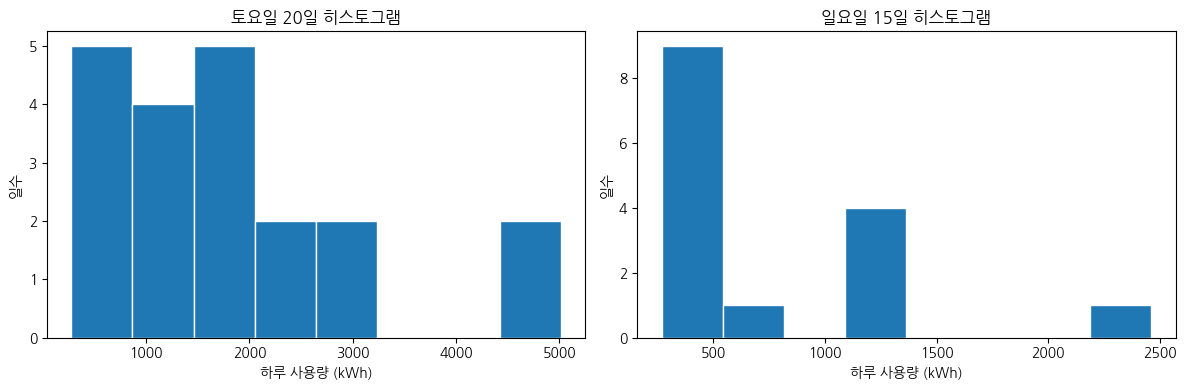

토요일 Shapiro-Wilk p값: 0.0161 / 일요일 Shapiro-Wilk p값: 0.0003
토요일 중앙값: 1621.4 kWh / 일요일 중앙값: 294.4 kWh
U 통계량: 241.0 / p값: 0.0026


In [11]:
# [예제] 토요일과 일요일의 하루 전력 사용량을 비교한다. 토요일과 일요일은 서로 다른 날이다
# 귀무가설(H₀): 토요일과 일요일 하루 전력 사용량의 분포는 같다. (F₁ = F₂)
# 대립가설(H₁): 토요일과 일요일 하루 전력 사용량의 분포는 다르다. (F₁ ≠ F₂)
# 유의수준 α = 0.05, 양측
weekend = data.loc[data["WeekStatus"] == "Weekend"]                                          # 주말 기록만
weekend_daily = weekend.groupby(["day", "Day_of_week"])["Usage_kWh"].sum().reset_index()     # 날짜별 하루 사용량
saturday = weekend_daily.loc[weekend_daily["Day_of_week"] == "Saturday", "Usage_kWh"]
sunday = weekend_daily.loc[weekend_daily["Day_of_week"] == "Sunday", "Usage_kWh"]

sat = saturday.sample(n=20, replace=False, random_state=0)       # 토요일 20일
sun = sunday.sample(n=15, replace=False, random_state=0)         # 일요일 15일

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(sat, bins=8, edgecolor="white")
axes[0].set(title="토요일 20일 히스토그램", xlabel="하루 사용량 (kWh)", ylabel="일수")
axes[1].hist(sun, bins=8, edgecolor="white")                     # 오른쪽 꼬리가 긴지 확인
axes[1].set(title="일요일 15일 히스토그램", xlabel="하루 사용량 (kWh)", ylabel="일수")
plt.tight_layout()
plt.show()

print("토요일 Shapiro-Wilk p값:", round(stats.shapiro(sat).pvalue, 4), "/ 일요일 Shapiro-Wilk p값:", round(stats.shapiro(sun).pvalue, 4))
print("토요일 중앙값:", round(sat.median(), 1), "kWh / 일요일 중앙값:", round(sun.median(), 1), "kWh")

mw_result = stats.mannwhitneyu(sat, sun)                          # Mann-Whitney U 검정. 기본값이 양측
print("U 통계량:", mw_result.statistic, "/ p값:", round(mw_result.pvalue, 4))

# [결과]
# - Shapiro-Wilk 토요일 p = 0.0161, 일요일 p = 0.0003 → 두 집단에서 정규성 가설이 기각된다. 여기서는 평균이 아니라 토요일과 일요일의 사용량 분포를 비교하기 위해 Mann-Whitney U 검정을 적용한다
# - 중앙값 토요일 1,621 kWh, 일요일 294 kWh. p = 0.0026
# - 통계적 결론 : p = 0.0026 < 0.05 이므로 귀무가설을 기각한다
# - 사실적 결론 : 토요일과 일요일 하루 전력 사용량의 분포는 다르다고 볼 통계적 근거가 있다. 표본에서 토요일 사용량이 일요일보다 크게 나오는 경향이 있다 (중앙값 토요일 1,621 kWh · 일요일 294 kWh, 토요일 20일 · 일요일 15일)

## 6. 정리 : 세 가지 자료 구조와 검정

| 검정 | 자료 구조 | 분포 확인 대상 | 평균을 검정할 때 | 비모수 검정을 고려할 때 |
|---|---|---|---|---|
| 일표본 | 한 집단 vs 기준값 | 측정값 | `stats.ttest_1samp(x, 기준값)` | `stats.wilcoxon(x - 기준값)` |
| 대응표본 | 같은 대상의 두 측정값 | 차이값 | `stats.ttest_rel(after, before)` | `stats.wilcoxon(after, before)` |
| 독립표본 | 서로 다른 두 집단 | 두 집단 각각 | `stats.ttest_ind(A, B, equal_var=False)` | `stats.mannwhitneyu(A, B)` |

Wilcoxon 부호순위검정은 측정값 − 기준값(대응표본은 차이값)의 분포가 0을 중심으로 대칭인지 검정한다. 차이값 분포의 대칭성 가정을 고려해야 하며, 대칭성이 심하게 어긋날 때는 검정의 적절성을 다시 검토한다. 독립표본의 Mann-Whitney U 검정은 평균 차이 검정과 목적이 다르다.

### 독립표본 검정 고르기

정규성은 집단마다 모양을 따로 보고, 등분산은 두 집단의 퍼짐을 비교한다. 서로 다른 확인 항목이다.

| 상황 | 정규성 | 등분산 | 선택 |
|---|---|---|---|
| 두 집단 모두 종 모양, 폭도 비슷 | O | O | Welch (Student와 결과가 거의 같다) |
| 두 집단 모두 종 모양, 폭이 다름 | O | X | Welch (예 : 상반기 · 하반기) |
| 집단의 분포가 크게 치우치거나 극단값이 있음 | 확인 필요 | 상관없음 | 목표가 평균 비교면 Welch 적용의 적절성을 먼저 검토; 분포 비교가 목표면 Mann-Whitney 고려 (예 : 토요일 · 일요일) |

등분산은 Welch t검정이 계산에 반영하므로 따로 확인하지 않는다. 검정은 정규성 p값 하나로 정하지 않는다. 먼저 비교할 대상(평균인지, 분포인지)을 정하고, 표본 크기 · 분포 모양 · 극단값을 함께 본다.

### 해석 시 유의점

| 항목 | 해석 기준 |
|---|---|
| 독립표본과 대응표본 | 같은 대상을 두 번 측정했거나 두 집단의 관측값이 일대일로 대응하면 대응표본, 서로 다른 대상으로 이루어진 두 집단이어서 대응 관계가 없으면 독립표본으로 분석한다 |
| `equal_var=False` | Welch t검정을 지정하는 인자다. 생략하면 기본값 `equal_var=True`가 적용되어 등분산을 가정하는 Student t검정으로 계산된다 |
| Mann-Whitney U 검정의 결론 | 평균이 아니라 순위로 두 집단의 분포를 비교한다. |
공식 문서 : [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html) · [scipy.stats.mannwhitneyu](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html)